## 1. Memuat Dataset

In [2]:
import pandas as pd
import numpy as np

# Memuat dataset ke dalam DataFrame
data = pd.read_csv('/content/Teen_Mental_Health_Dataset_DIRUSAK.csv')
print(f"Dataset berhasil dimuat. Ukuran awal: {data.shape}")
data.head()

Dataset berhasil dimuat. Ukuran awal: (1260, 13)


,age,gender,daily_social_media_hours,platform_usage,sleep_hours,screen_time_before_sleep,academic_performance,physical_activity,social_interaction_level,stress_level,anxiety_level,addiction_level,depression_label
0,14,male,7.9,Instgrm,7.4,2.9,3.01,1.5,low,2,2,1,0
1,19,female,1.9,TikTok,8.0,2.9,3.22,0.8,high,8,1,10,0
2,17,female,1.3,Instagram,7.6,0.5,3.92,0.0,high,2,4,2,0
3,15,male,7.4,tik_tok,6.9,1.6,3.48,0.8,medium,1,7,9,0
4,15,female,4.7,BOTH,4.9,3.0,2.37,1.4,medium,3,5,2,0


## 2. Menghapus Duplikat

In [3]:
# Menghapus baris yang identik di semua kolom
sebelum = len(data)
data.drop_duplicates(inplace=True)
sesudah = len(data)
print(f"Duplikat dihapus: {sebelum - sesudah} baris | Sisa: {sesudah} baris")

Duplikat dihapus: 60 baris | Sisa: 1200 baris


## 3. Menangani Nilai Kosong

In [4]:
# Cek jumlah nilai kosong sebelum dibersihkan
print("Nilai kosong per kolom:")
print(data.isnull().sum())

# Hapus semua baris yang mengandung nilai NaN
data.dropna(inplace=True)
print(f"\nDataset setelah hapus NaN: {data.shape}")

Nilai kosong per kolom:
age                           0
gender                        0
daily_social_media_hours    144
platform_usage              144
sleep_hours                 140
screen_time_before_sleep      0
academic_performance        144
physical_activity             0
social_interaction_level      0
stress_level                  0
anxiety_level                 0
addiction_level               0
depression_label              0
dtype: int64

Dataset setelah hapus NaN: (1056, 13)


## 4. Standardisasi Teks pada Kolom `platform_usage`

In [5]:
# Ubah semua teks ke huruf kecil terlebih dahulu
data['platform_usage'] = data['platform_usage'].str.strip().str.lower()

# Peta koreksi untuk nilai yang tidak konsisten
koreksi_platform = {
    'instgrm':      'instagram',
    'instagram!!!': 'instagram',
    'tik_tok':      'tiktok',
    'tiktok!!!':    'tiktok',
    'both!!!':      'both'
}
data['platform_usage'] = data['platform_usage'].replace(koreksi_platform)

print("Nilai unik platform_usage setelah standardisasi:")
print(data['platform_usage'].value_counts())

Nilai unik platform_usage setelah standardisasi:
platform_usage
instagram    362
tiktok       349
both         345
Name: count, dtype: int64


## 5. Validasi Rentang Nilai Numerik

In [6]:
# Hapus baris dengan nilai usia negatif
data = data[data['age'] >= 0]

# Hapus baris dengan jam tidur yang tidak realistis (> 12 jam)
data = data[data['sleep_hours'] <= 12]

print(f"Dimensi dataset setelah validasi numerik: {data.shape}")

Dimensi dataset setelah validasi numerik: (972, 13)


## 6. Ringkasan Dataset Bersih

In [8]:
print("Dimensi akhir dataset yang sudah bersih:", data.shape)
print("\nInfo tipe data:")
data.info()

Dimensi akhir dataset yang sudah bersih: (972, 15)

Info tipe data:
<class 'pandas.core.frame.DataFrame'>
Index: 972 entries, 0 to 1198
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       972 non-null    int64  
 1   gender                    972 non-null    int64  
 2   daily_social_media_hours  972 non-null    float64
 3   sleep_hours               972 non-null    float64
 4   screen_time_before_sleep  972 non-null    float64
 5   academic_performance      972 non-null    float64
 6   physical_activity         972 non-null    float64
 7   social_interaction_level  972 non-null    int64  
 8   stress_level              972 non-null    int64  
 9   anxiety_level             972 non-null    int64  
 10  addiction_level           972 non-null    int64  
 11  depression_label          972 non-null    int64  
 12  platform_usage_both       972 non-null    int64  
 13  p

## 7. Konstruksi Data (Feature Encoding)

In [7]:
# a. Ordinal Encoding: 'social_interaction_level'
# Memetakan kategori bertingkat ke angka ordinal
urutan_interaksi = {'low': 0, 'medium': 1, 'high': 2}
data['social_interaction_level'] = data['social_interaction_level'].map(urutan_interaksi)

# b. Binary Encoding: 'gender'
# Konversi teks gender ke nilai biner (0 = female, 1 = male)
peta_gender = {'female': 0, 'male': 1}
data['gender'] = data['gender'].map(peta_gender)

# c. One-Hot Encoding: 'platform_usage'
# Platform tidak memiliki urutan, sehingga dipecah menjadi kolom dummy
data = pd.get_dummies(data, columns=['platform_usage'], dtype=int)

print("Kolom setelah encoding:")
print(data.columns.tolist())
data.head()

Kolom setelah encoding:
['age', 'gender', 'daily_social_media_hours', 'sleep_hours', 'screen_time_before_sleep', 'academic_performance', 'physical_activity', 'social_interaction_level', 'stress_level', 'anxiety_level', 'addiction_level', 'depression_label', 'platform_usage_both', 'platform_usage_instagram', 'platform_usage_tiktok']


,age,gender,daily_social_media_hours,sleep_hours,screen_time_before_sleep,academic_performance,physical_activity,social_interaction_level,stress_level,anxiety_level,addiction_level,depression_label,platform_usage_both,platform_usage_instagram,platform_usage_tiktok
0,14,1,7.9,7.4,2.9,3.01,1.5,0,2,2,1,0,0,1,0
1,19,0,1.9,8.0,2.9,3.22,0.8,2,8,1,10,0,0,0,1
2,17,0,1.3,7.6,0.5,3.92,0.0,2,2,4,2,0,0,1,0
3,15,1,7.4,6.9,1.6,3.48,0.8,1,1,7,9,0,0,0,1
4,15,0,4.7,4.9,3.0,2.37,1.4,1,3,5,2,0,1,0,0


## 8. Business Intelligence (Visualisasi & EDA)

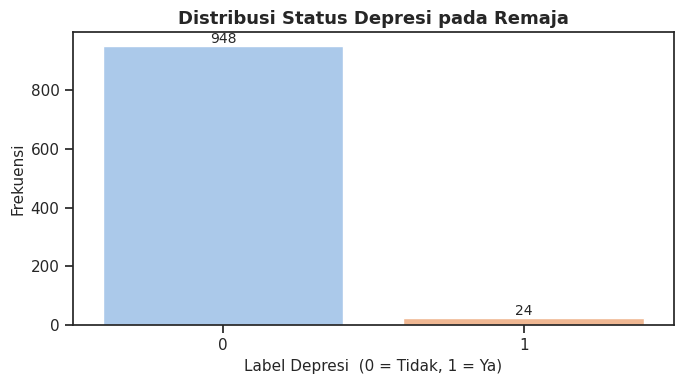

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="ticks")

# --- Grafik 1: Distribusi Depresi ---
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(
    data=data,
    x='depression_label',
    palette='pastel',
    hue='depression_label',
    legend=False,
    ax=ax
)
ax.set_title('Distribusi Status Depresi pada Remaja', fontsize=13, fontweight='bold')
ax.set_xlabel('Label Depresi  (0 = Tidak, 1 = Ya)', fontsize=11)
ax.set_ylabel('Frekuensi', fontsize=11)

# Tambahkan label angka di atas tiap bar
for container in ax.containers:
    ax.bar_label(container, fontsize=10)

plt.tight_layout()
plt.show()

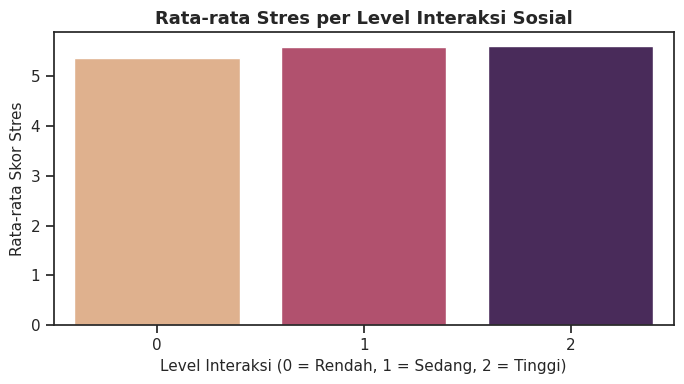

In [10]:
# --- Grafik 2: Rata-rata Stres berdasarkan Interaksi Sosial ---
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(
    data=data,
    x='social_interaction_level',
    y='stress_level',
    palette='flare',
    hue='social_interaction_level',
    legend=False,
    ax=ax,
    errorbar=None
)
ax.set_title('Rata-rata Stres per Level Interaksi Sosial', fontsize=13, fontweight='bold')
ax.set_xlabel('Level Interaksi (0 = Rendah, 1 = Sedang, 2 = Tinggi)', fontsize=11)
ax.set_ylabel('Rata-rata Skor Stres', fontsize=11)
plt.tight_layout()
plt.show()

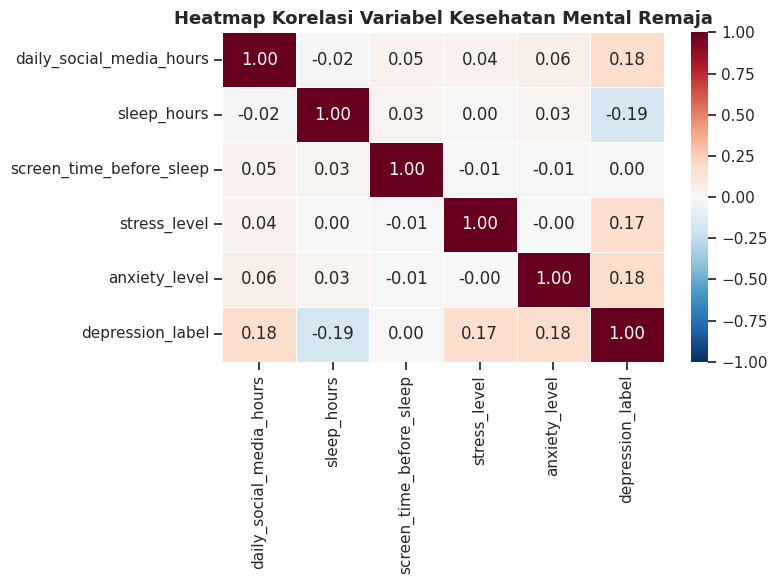

In [28]:
# --- Grafik 3: Heatmap Korelasi ---
fitur_analisis = [
    'daily_social_media_hours', 'sleep_hours',
    'screen_time_before_sleep', 'stress_level',
    'anxiety_level', 'depression_label'
]
matriks_korelasi = data[fitur_analisis].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    matriks_korelasi,
    annot=True,
    cmap='RdBu_r',
    fmt=".2f",
    linewidths=0.4,
    vmin=-1, vmax=1,
    ax=ax
)
ax.set_title('Heatmap Korelasi Variabel Kesehatan Mental Remaja', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 9. Visualisasi Data

Tahap ini menampilkan visualisasi eksploratif untuk memahami distribusi, korelasi,
dan pola dalam dataset kesehatan mental remaja yang telah bersih dan ter-encode.

In [15]:
jumlah_duplikat = data.duplicated().sum()
print(f"Jumlah duplikat pada dataset bersih: {jumlah_duplikat}")
if jumlah_duplikat == 0:
    print(" Dataset bersih — tidak ada baris duplikat.")
else:
    print(f" Masih ada {jumlah_duplikat} baris duplikat — pertimbangkan untuk menghapusnya.")
print(f"Shape dataset saat ini: {data.shape}")

Jumlah duplikat pada dataset bersih: 0
 Dataset bersih — tidak ada baris duplikat.
Shape dataset saat ini: (972, 15)


### 9.2 Heatmap Korelasi Antar Kolom Numerik

Menampilkan kekuatan dan arah korelasi antar **seluruh** kolom numerik setelah encoding.

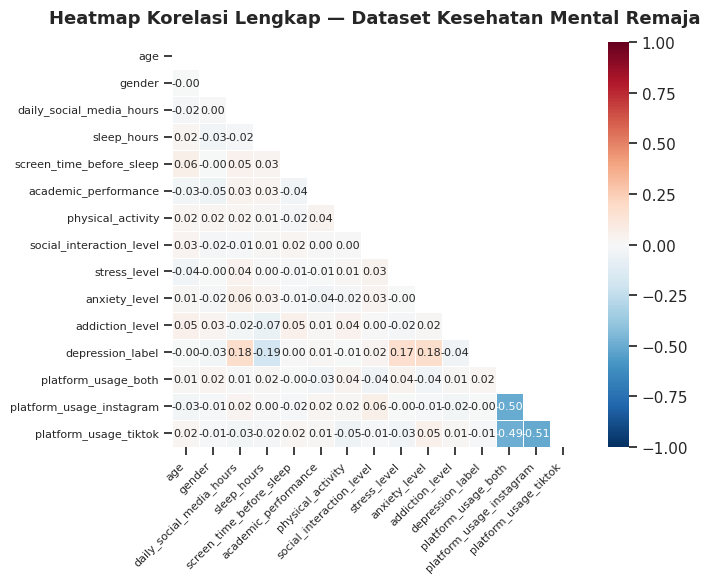

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='ticks')

numeric_cols = data.select_dtypes(include='number').columns.tolist()
corr = data[numeric_cols].corr()

plt.figure(figsize=(8, 6))
mask = __import__('numpy').triu(__import__('numpy').ones_like(corr, dtype=bool))
sns.heatmap(
    corr,
    mask=mask,
    annot=True, fmt='.2f',
    cmap='RdBu_r', center=0,
    vmin=-1, vmax=1,
    linewidths=0.4,
    annot_kws={'size': 8},
    square=True
)
plt.title('Heatmap Korelasi Lengkap — Dataset Kesehatan Mental Remaja',
          fontsize=13, fontweight='bold', pad=14)
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.savefig('heatmap_korelasi_lengkap.png', dpi=150, bbox_inches='tight')
plt.show()

### 9.3 Bar Chart — Jumlah Pengguna per Platform Media Sosial

Membandingkan jumlah remaja yang menggunakan masing-masing platform media sosial.

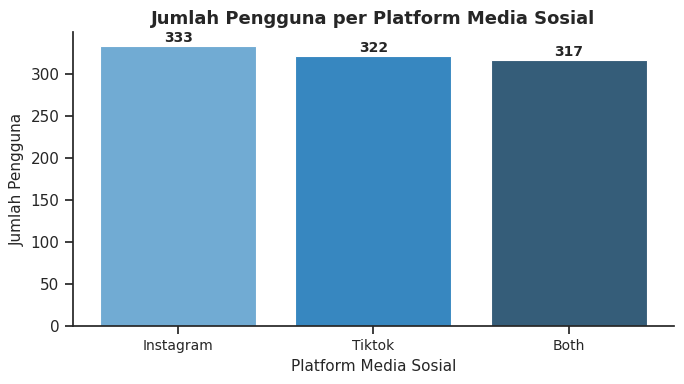

In [30]:
# Identifikasi kolom platform dari hasil One-Hot Encoding
platform_cols = [c for c in data.columns if c.startswith('platform_usage_')]

if platform_cols:
    platform_counts = data[platform_cols].sum().sort_values(ascending=False)
    labels = [c.replace('platform_usage_', '').capitalize() for c in platform_counts.index]
else:
    raise ValueError("Kolom platform_usage tidak ditemukan. Pastikan sel encoding sudah dijalankan.")

palette = sns.color_palette('Blues_d', len(platform_counts))

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(labels, platform_counts.values, color=palette, edgecolor='white', linewidth=0.8)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        str(int(bar.get_height())),
        ha='center', va='bottom', fontsize=10, fontweight='bold'
    )

ax.set_title('Jumlah Pengguna per Platform Media Sosial', fontsize=13, fontweight='bold')
ax.set_xlabel('Platform Media Sosial', fontsize=11)
ax.set_ylabel('Jumlah Pengguna', fontsize=11)
ax.tick_params(axis='x', labelsize=10)
sns.despine()
plt.tight_layout()
plt.savefig('barchart_platform_usage.png', dpi=150, bbox_inches='tight')
plt.show()


### 9.4 Line Chart — Tren Rata-rata Tingkat Stres & Kecemasan per Jam Media Sosial

Menampilkan tren tingkat stres dan kecemasan seiring bertambahnya jam penggunaan media sosial per hari.

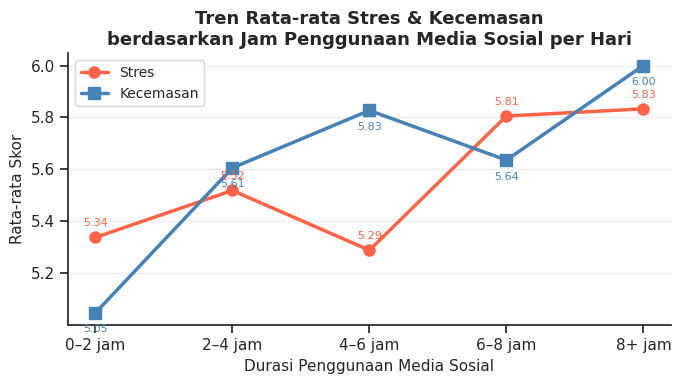

In [32]:
import numpy as np

# Buat bin jam media sosial (0-2, 2-4, 4-6, 6-8, 8+)
bins   = [0, 2, 4, 6, 8, data['daily_social_media_hours'].max() + 1]
labels_bin = ['0–2 jam', '2–4 jam', '4–6 jam', '6–8 jam', '8+ jam']
data['sm_bin'] = pd.cut(data['daily_social_media_hours'], bins=bins, labels=labels_bin, right=False)

trend = data.groupby('sm_bin', observed=True)[['stress_level', 'anxiety_level']].mean().reset_index()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(trend['sm_bin'].astype(str), trend['stress_level'],
        marker='o', markersize=8, linewidth=2.5, color='tomato', label='Stres')
ax.plot(trend['sm_bin'].astype(str), trend['anxiety_level'],
        marker='s', markersize=8, linewidth=2.5, color='steelblue', label='Kecemasan')

for _, row in trend.iterrows():
    ax.annotate(f"{row['stress_level']:.2f}",
                xy=(str(row['sm_bin']), row['stress_level']),
                xytext=(0, 8), textcoords='offset points',
                ha='center', fontsize=8, color='tomato')
    ax.annotate(f"{row['anxiety_level']:.2f}",
                xy=(str(row['sm_bin']), row['anxiety_level']),
                xytext=(0, -14), textcoords='offset points',
                ha='center', fontsize=8, color='steelblue')

ax.set_title('Tren Rata-rata Stres & Kecemasan\nberdasarkan Jam Penggunaan Media Sosial per Hari',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Durasi Penggunaan Media Sosial', fontsize=11)
ax.set_ylabel('Rata-rata Skor', fontsize=11)
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.35)
sns.despine()
plt.tight_layout()
plt.savefig('linechart_stres_kecemasan.png', dpi=150, bbox_inches='tight')
plt.show()

# Hapus kolom bantu
data.drop(columns=['sm_bin'], inplace=True)

### 9.5 Pie Chart — Distribusi Status Depresi pada Remaja

Menampilkan proporsi remaja yang terindikasi depresi vs tidak.

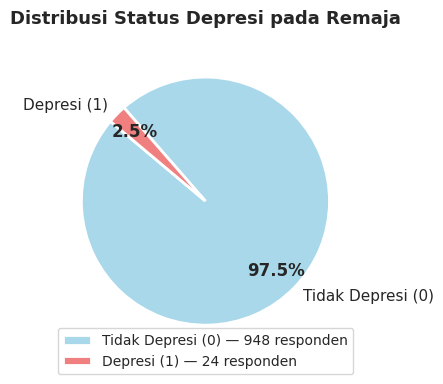

In [34]:
depresi_counts = data['depression_label'].value_counts().sort_index()
pie_labels     = ['Tidak Depresi (0)', 'Depresi (1)']
pie_colors     = ['#a8d8ea', '#f08080']

fig, ax = plt.subplots(figsize=(7, 4))
wedges, texts, autotexts = ax.pie(
    depresi_counts.values,
    labels=pie_labels,
    autopct='%1.1f%%',
    startangle=140,
    colors=pie_colors,
    pctdistance=0.80,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)
for at in autotexts:
    at.set_fontsize(12)
    at.set_fontweight('bold')

ax.set_title('Distribusi Status Depresi pada Remaja',
             fontsize=13, fontweight='bold', pad=16)

# Legend dengan jumlah absolut
legend_labels = [f"{lbl} — {cnt} responden"
                 for lbl, cnt in zip(pie_labels, depresi_counts.values)]
ax.legend(wedges, legend_labels, loc='lower center',
          bbox_to_anchor=(0.5, -0.08), fontsize=10)

plt.tight_layout()
plt.savefig('piechart_depresi.png', dpi=150, bbox_inches='tight')
plt.show()


### 9.6 Word Cloud — Kata Kunci Populer Platform Media Sosial

Menampilkan platform mana yang paling sering digunakan oleh responden, dengan ukuran kata sebanding frekuensinya.

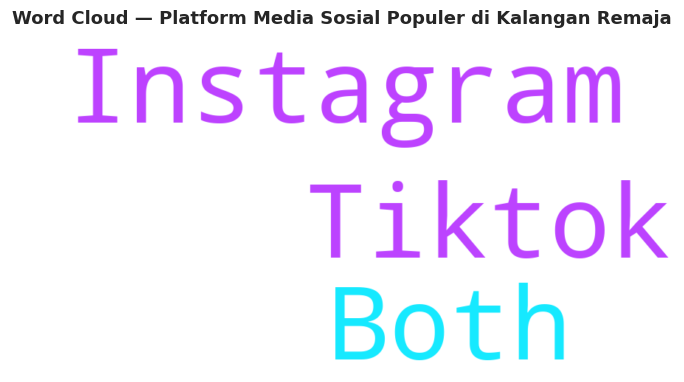

In [36]:
try:
    from wordcloud import WordCloud
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'wordcloud', '-q'])
    from wordcloud import WordCloud

# Bangun frekuensi dari kolom OHE platform
platform_cols = [c for c in data.columns if c.startswith('platform_usage_')]
freq_dict = {
    col.replace('platform_usage_', '').capitalize(): int(data[col].sum())
    for col in platform_cols
}

wc = WordCloud(
    width=900, height=450,
    background_color='white',
    colormap='cool',
    max_font_size=140,
    min_font_size=22,
    prefer_horizontal=0.85,
    random_state=42
).generate_from_frequencies(freq_dict)

plt.figure(figsize=(7, 5))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud — Platform Media Sosial Populer di Kalangan Remaja',
          fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig('wordcloud_platform.png', dpi=150, bbox_inches='tight')
plt.show()


### 9.7 Tabel Statistik Deskriptif Variabel Utama

In [22]:
kolom_utama = [
    'age', 'daily_social_media_hours', 'sleep_hours',
    'screen_time_before_sleep', 'stress_level',
    'anxiety_level', 'depression_label'
]
kolom_ada = [c for c in kolom_utama if c in data.columns]

print("=" * 60)
print("   STATISTIK DESKRIPTIF VARIABEL UTAMA")
print("=" * 60)
print(data[kolom_ada].describe().round(2).to_string())

print("\n" + "=" * 60)
print("   RINGKASAN AKHIR DATASET")
print("=" * 60)
print(f"Total baris     : {len(data)}")
print(f"Total kolom     : {len(data.columns)}")
print(f"Missing values  : {data.isnull().sum().sum()}")
print(f"Duplikat        : {data.duplicated().sum()}")

   STATISTIK DESKRIPTIF VARIABEL UTAMA
          age  daily_social_media_hours  sleep_hours  screen_time_before_sleep  stress_level  anxiety_level  depression_label
count  972.00                    972.00       972.00                    972.00        972.00         972.00            972.00
mean    15.92                      4.55         6.45                      1.74          5.52           5.61              0.02
std      2.03                      2.06         1.44                      0.71          2.92           2.86              0.16
min     13.00                      1.00         4.00                      0.50          1.00           1.00              0.00
25%     14.00                      2.70         5.20                      1.10          3.00           3.00              0.00
50%     16.00                      4.50         6.50                      1.80          5.00           6.00              0.00
75%     18.00                      6.40         7.62                      2.32 